# Лабораторная работа 2. Мультимодальные модели: новость + числа + свечной график (SBER)

Ноутбук закрывает **задания 3, 4, 5** (задания 1–2 уже сделаны, данные лежат в `out/` после `task2_sync.py build`).

**Как устроен ноутбук**
1. Окружение и конфиг, загрузка данных из задания 2, сжатие текста.
2. Фреймворк: функция `run_model(cfg)` делает **4 прогона** одной модели: только новость, только числа, только график, все три вместе. Выдаёт метрики, калибровку, устойчивость к пропаже модальности, latency и стоимость.
3. **7 ячеек-прогонов**: в каждой только конфиг модели и вызов функции. Модели запускаются по очереди, память GPU освобождается после каждой (T4, 15 ГБ).
4. Четыре итоговые таблицы (новость / числа / график / все три), многокритериальная оценка (задание 5), выбор лучшей модели.
5. Абляции, permutation test, режимы, анализ ошибок для лучшей модели.
6. Задание 4: та же схема на другой компании (не из ВКР), перенос и дообучение.
7. Экспорт артефактов (задание 7) и черновик вывода (задание 6).

**Что такое «модель» здесь.** Задание разрешает «модели или схемы интеграции». 4 схемы модульные (замороженные энкодеры текста и графика, числовые признаки, разные способы слияния: concat, late, gated, cross-attention), 3 схемы — реальные VLM, которым новость, таблица котировок и график подаются одним промптом. Все энкодеры заморожены, обучаются только лёгкие головы: это единственный способ уложить 7 схем в T4 и пару часов.

**Порядок запуска:** ячейки сверху вниз. Эмбеддинги кэшируются на диск (`cache/`), после обрыва Colab прогоны продолжаются быстро.

**Что нужно в папке `WORK`** (на Google Drive: `MyDrive/lab2`): `out/` (samples.csv, img/, exclusions.csv...), `data/candles.csv`, `data/news.csv`, `task2_sync.py`.

In [1]:
!pip -q install -U "transformers>=4.50" accelerate sentence-transformers tabulate pyarrow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.8/40.8 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 79.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 45.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 13.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 0. Окружение и конфиг

In [2]:
import os, sys, json, time, math, gc, hashlib, re, random, warnings, pickle, itertools, copy
import numpy as np, pandas as pd
from PIL import Image
warnings.filterwarnings("ignore")
import torch
from IPython.display import display

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
WORK = os.environ.get("LAB2_WORK") or ("/content/drive/MyDrive/ВКР/Лабораторная Работа 2" if IN_COLAB else "./lab2")
if IN_COLAB and WORK.startswith("/content/drive"):
    drive.mount("/content/drive")

SBER_OUT    = f"{WORK}/out"
CANDLES_CSV = f"{WORK}/data/candles.csv"
NEWS_CSV    = f"{WORK}/data/news.csv"
ART, CACHE  = f"{WORK}/artifacts", f"{WORK}/cache"
os.makedirs(ART, exist_ok=True); os.makedirs(CACHE, exist_ok=True)
for p in (f"{SBER_OUT}/samples.csv", CANDLES_CSV):
    assert os.path.exists(p), f"Нет файла {p}."

# ---------- параметры эксперимента ----------
SEED = 42
WINDOW = 20
TEXT_MODE = "summary"
LEAD_CHARS = 500
SUM_MODEL = "IlyaGusev/rut5_base_sum_gazeta"
MAX_TOKENS_TEXT = 256          # для энкодеров текста
N_BOOT, N_PERM = 2000, 5000    # блочный bootstrap и permutation test (блок = якорная дата)
HYP_GAIN = 0.03                # гипотеза: прирост macro-F1 >= 0.03
GPU_USD_PER_HOUR = 10          # ПРЕДПОЛОЖЕНИЕ для оценки стоимости: 10 условных единиц
MODE_MODS = {"text": ("text",), "num": ("num",), "img": ("img",), "all": ("text", "num", "img")}
MODE_RU = {"text": "только новость", "num": "только числа", "img": "только график", "all": "все три модальности"}

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "GPU не найден")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda Tesla T4


In [3]:
try:
    from tqdm.auto import tqdm
except Exception:
    tqdm = lambda x, **k: x
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, matthews_corrcoef, log_loss

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

def free_gpu():
    gc.collect()
    try:
        torch.cuda.empty_cache()
    except Exception:
        pass

def sync():
    try:
        if DEVICE == "cuda": torch.cuda.synchronize()
    except Exception:
        pass

JOURNAL_PATH = f"{ART}/params_journal.jsonl"
def jlog(**kw):
    """Журнал параметров (задание 3): одна строка JSON на прогон."""
    kw["ts"] = time.strftime("%Y-%m-%d %H:%M:%S")
    with open(JOURNAL_PATH, "a", encoding="utf-8") as f:
        f.write(json.dumps(kw, ensure_ascii=False, default=str) + "\n")

def hf_load(cls, name, dtype, **kw):
    """from_pretrained с учётом переименования torch_dtype -> dtype в разных версиях transformers."""
    try:
        return cls.from_pretrained(name, dtype=dtype, **kw)
    except TypeError:
        return cls.from_pretrained(name, torch_dtype=dtype, **kw)

def _safe(s): return re.sub(r"[^0-9A-Za-z._-]+", "_", s)[:70]

def cached_array(key, fn, n_items):
    """Кэш признаков на диске: после обрыва Colab ничего не пересчитывается. Возвращает (массив, {sec, n})."""
    base = os.path.join(CACHE, f"{_safe(key)}_{hashlib.md5(key.encode()).hexdigest()[:10]}")
    if os.path.exists(base + ".npy") and os.path.exists(base + ".json"):
        return np.load(base + ".npy"), json.load(open(base + ".json"))
    t0 = time.time(); arr = np.asarray(fn()); sync(); sec = time.time() - t0
    meta = {"key": key, "sec": sec, "n": int(n_items)}
    np.save(base + ".npy", arr); json.dump(meta, open(base + ".json", "w"))
    return arr, meta

seed_all()
import platform, importlib.metadata as _im
def _ver(p):
    try: return _im.version(p)
    except Exception: return "?"
ENV_INFO = {"python": platform.python_version(), **{p: _ver(p) for p in ("torch", "transformers", "sentence-transformers", "scikit-learn", "pandas", "numpy")}}
jlog(event="env", **ENV_INFO, device=DEVICE, seed=SEED, text_mode=TEXT_MODE, window=WINDOW)
print(ENV_INFO)

{'python': '3.13.15', 'torch': '2.11.0+cu130', 'transformers': '5.20.0', 'sentence-transformers': '6.1.0', 'scikit-learn': '1.6.1', 'pandas': '2.2.3', 'numpy': '2.1.3'}


## 1. Данные из задания 2: образцы, числовое окно, сжатие текста
Образец = новость × тикер. Модальности: **текст** (сжатая новость), **числа** (окно 20 свечей, только по прошлому), **график** (PNG из `out/img`). Строки `embargo` отбрасываются, split берётся из `samples.csv` как есть.

In [4]:
# ---------- числовые признаки по окну OHLCV (всё относительное: без абсолютного уровня цены) ----------
def stats_vec(w):
    o, h, l, c, v = (w[k].to_numpy(float) for k in ("open", "high", "low", "close", "volume"))
    lr = np.diff(np.log(c)); vm = v.mean() + 1.0
    g = np.clip(lr[-14:], 0, None).mean(); d = np.clip(-lr[-14:], 0, None).mean()
    f = list(lr[-5:])                                                   # 0-4: последние 5 лог-доходностей (4 = вчерашняя)
    f += [c[-1]/c[-6]-1, c[-1]/c[-11]-1, c[-1]/c[0]-1]                  # 5-7: доходность за 5/10/20 дней
    f += [lr[-5:].std(), lr.std()]                                      # 8-9: волатильность (9 = vol20)
    f += [(h[-1]-l[-1])/c[-1], ((h-l)/c)[-5:].mean(), (c[-1]-o[-1])/o[-1], o[-1]/c[-2]-1]
    f += [c[-1]/h.max()-1, c[-1]/l.min()-1]                             # положение относительно максимума и минимума окна
    f += [np.log((v[-1]+1)/vm), np.log((v[-5:].mean()+1)/vm)]           # объём
    f += [g/(g+d+1e-12), (lr[-10:] > 0).mean()]                         # RSI-подобный, доля растущих дней
    return np.array(f, float)

def window_vec(w):
    o, h, l, c, v = (w[k].to_numpy(float) for k in ("open", "high", "low", "close", "volume"))
    ref = c[-1]
    return np.concatenate([o/ref-1, h/ref-1, l/ref-1, c/ref-1, np.log((v+1)/(v.mean()+1))])

def window_text(w):
    """Таблица котировок для VLM (аналог идеи TaPas/Time-LLM: числа как текст). Изменения в % к предыдущему закрытию."""
    o, h, l, c, v = (w[k].to_numpy(float) for k in ("open", "high", "low", "close", "volume"))
    prev = np.r_[o[0], c[:-1]]; vm = v.mean() + 1.0
    return "\n".join(f"{k-len(c)+1:>3}: O{(o[k]/prev[k]-1)*100:+.1f} H{(h[k]/prev[k]-1)*100:+.1f} "
                     f"L{(l[k]/prev[k]-1)*100:+.1f} C{(c[k]/prev[k]-1)*100:+.1f} V{(v[k]+1)/vm:.1f}" for k in range(len(c)))

# ---------- текст: сжатие и эвристика утечки ----------
def lead_text(t, n=LEAD_CHARS):
    t = (t or "").strip()
    if len(t) <= n: return t
    cut = t[:n]; k = max(cut.rfind(". "), cut.rfind("! "), cut.rfind("? "))
    return cut[:k+1] if k > n*0.5 else cut

LEAK_RE = re.compile(r"(по итогам (торгов|дня|сессии)|торги (завершил|закрыл)|индекс (мосбиржи|ртс)[^.]{0,40}(вырос|снизил|упал)"
                     r"|акции [^.]{0,40}(выросли|упали|подешевели|подорожали|снизились|подскочили)|котировки [^.]{0,40}(выросли|упали|снизились))", re.I)

def summarize_texts(texts, bs=16):
    from transformers import AutoTokenizer, T5ForConditionalGeneration
    tok = AutoTokenizer.from_pretrained(SUM_MODEL)
    m = hf_load(T5ForConditionalGeneration, SUM_MODEL, torch.float32).to(DEVICE).eval()   # T5 в fp16 даёт NaN: считаем в fp32
    order = np.argsort([len(t) for t in texts]); out = [None] * len(texts)
    for s in tqdm(range(0, len(texts), bs), desc="сжатие текста"):
        ids = order[s:s+bs]
        enc = tok([texts[i] for i in ids], max_length=600, truncation=True, padding=True, return_tensors="pt").to(DEVICE)
        with torch.inference_mode():
            g = m.generate(**enc, max_new_tokens=96, num_beams=2, no_repeat_ngram_size=4)
        for i, t in zip(ids, tok.batch_decode(g, skip_special_tokens=True)): out[i] = t
    del m; free_gpu()
    return out

def prepare_text(ds):
    df = ds.df
    if TEXT_MODE == "summary":
        path = f"{CACHE}/summary_{ds.name}.json"
        cache = json.load(open(path)) if os.path.exists(path) else {}
        todo = [i for i, s in enumerate(df.sample_id.values) if s not in cache]
        if todo:
            try:
                outs = summarize_texts([df.text.values[i] for i in todo])
                for i, o in zip(todo, outs): cache[df.sample_id.values[i]] = o
                json.dump(cache, open(path, "w"), ensure_ascii=False)
            except Exception as e:
                print("[WARN] суммаризатор недоступен, использую lead:", repr(e)[:200])
        short = [cache.get(s) or lead_text(t) for s, t in zip(df.sample_id.values, df.text.values)]
    else:
        short = [lead_text(t) for t in df.text.values]
    df["text_short"] = [s if str(s).strip() else "(пустой текст)" for s in short]
    df["leak_flag"] = df.text.map(lambda t: bool(LEAK_RE.search(t)))
    ds.tfp = hashlib.md5("|".join(df.text_short).encode()).hexdigest()[:8]
    print(f"[{ds.name}] текст готов: медиана {int(df.text.str.len().median())} -> {int(df.text_short.str.len().median())} символов; "
          f"эвристика утечки сработала в {df.leak_flag.mean():.1%} новостей")

# ---------- датасет ----------
class DS:
    def __init__(self, name, ticker, out_dir, candles):
        self.name, self.ticker, self.out_dir = name, ticker, out_dir
        df = pd.read_csv(f"{out_dir}/samples.csv", keep_default_na=False)
        df["published"] = pd.to_datetime(df["published"], utc=True).dt.tz_convert("Europe/Moscow")
        for c in ("anchor_date", "target_date"): df[c] = pd.to_datetime(df[c]).dt.date
        df["label"] = df["label"].astype(int); df["ret_next"] = df["ret_next"].astype(float)
        self.n_embargo = int((df["split"] == "embargo").sum())
        df = df[df["split"].isin(["train", "val", "test"])].sort_values(["anchor_date", "published"]).reset_index(drop=True)
        self.df = df
        self.cand = {t: g.sort_values("date").reset_index(drop=True) for t, g in candles.groupby("ticker")}
        self._pos = {t: {d: i for i, d in enumerate(g["date"])} for t, g in self.cand.items()}
        W = [self.window(t, a) for t, a in zip(df.ticker.values, df.anchor_date.values)]
        self.stats = np.nan_to_num(np.vstack([stats_vec(w) for w in W]))
        self.winv = np.nan_to_num(np.vstack([window_vec(w) for w in W]))
        self.tables = [window_text(w) for w in W]
        self.img_paths = [os.path.join(out_dir, p) for p in df.image.values]
        missing = [p for p in set(self.img_paths) if not os.path.exists(p)]
        assert not missing, f"нет {len(missing)} изображений, например {missing[:2]}"
        self.y = df.label.values
        self.idx = {s: np.where(df.split.values == s)[0] for s in ("train", "val", "test")}
        self.groups = pd.factorize(df.anchor_date.astype(str))[0]
        self.fp = hashlib.md5("|".join(df.sample_id).encode()).hexdigest()[:8]
        self.tfp = ""
    def window(self, t, a):
        i = self._pos[t][a]
        return self.cand[t].iloc[i - WINDOW + 1: i + 1]
    def num_block(self, kind):
        return {"stats": self.stats, "window": self.winv, "both": np.hstack([self.stats, self.winv])}[kind]

def read_candles(path):
    c = pd.read_csv(path); c["date"] = pd.to_datetime(c["date"]).dt.date
    return c

In [5]:
CANDLES = read_candles(CANDLES_CSV)
DS_MAIN = DS("SBER", "SBER", SBER_OUT, CANDLES)
d = DS_MAIN.df
print(f"образцов (без embargo): {len(d)}; embargo исключено: {DS_MAIN.n_embargo}; уникальных графиков: {len(set(DS_MAIN.img_paths))}")
print(d.groupby("split").agg(n=("label", "size"), start=("anchor_date", "min"), end=("anchor_date", "max"), up_share=("label", "mean")).round(3))

образцов (без embargo): 2890; embargo исключено: 2; уникальных графиков: 902
          n       start         end  up_share
split                                        
test    437  2024-02-13  2024-06-28     0.558
train  2020  2019-12-13  2023-08-21     0.517
val     433  2023-08-23  2024-02-08     0.577


In [6]:
# Сжатие текста моделью (в отчёте указано: текст слишком длинный). Результат кэшируется в cache/summary_SBER.json.
prepare_text(DS_MAIN)
display(DS_MAIN.df[["text", "text_short"]].head(3).assign(text=lambda x: x.text.str[:300]))

[SBER] текст готов: медиана 1729 -> 281 символов; эвристика утечки сработала в 1.5% новостей


,text,text_short
0,Сбербанк дал возможность клиентам кредитовать ...,Сбербанк запускает платформу для кредитования ...
1,Сбербанк и SberCloud запустили в эксплуатацию ...,Сбербанк и SberCloud запустили в эксплуатацию ...
2,Сбербанк получил пять наград премии RETAIL FIN...,Сбербанк получил пять наград премии RETAIL FIN...


## 2. Фреймворк: энкодеры, головы слияния, метрики, `run_model`

In [7]:
_ENC, _VLM_DTYPE = {}, {}
def release_all():
    _ENC.clear(); free_gpu()
def _dev_dtype(): return torch.float16 if DEVICE == "cuda" else torch.float32

# ---------- модульные энкодеры (заморожены) ----------
def _text_model(name):
    key = ("txt", name)
    if key not in _ENC:
        from sentence_transformers import SentenceTransformer
        m = SentenceTransformer(name, device=DEVICE); m.max_seq_length = MAX_TOKENS_TEXT
        if DEVICE == "cuda": m.half()
        _ENC[key] = m
    return _ENC[key]

def _encode_text_raw(name, texts, prefix="", bs=32):
    m = _text_model(name)
    e = m.encode([prefix + t for t in texts], batch_size=bs, normalize_embeddings=True, convert_to_numpy=True,
                 show_progress_bar=len(texts) > 200)
    return np.asarray(e, dtype=np.float32)

def _img_model(name):
    key = ("img", name)
    if key not in _ENC:
        from transformers import AutoModel, AutoImageProcessor
        proc = AutoImageProcessor.from_pretrained(name)
        m = hf_load(AutoModel, name, _dev_dtype())
        if hasattr(m, "vision_model"): m = m.vision_model      # CLIP / SigLIP: берём только визуальную башню
        _ENC[key] = (proc, m.to(DEVICE).eval())
    return _ENC[key]

def _encode_img_raw(name, paths, bs=64, proc_kw=None):
    proc, m = _img_model(name); dt = next(m.parameters()).dtype; out = []
    for s in range(0, len(paths), bs):
        ims = [Image.open(p).convert("RGB") for p in paths[s:s+bs]]
        px = proc(images=ims, return_tensors="pt", **(proc_kw or {}))["pixel_values"].to(DEVICE, dtype=dt)
        with torch.inference_mode():
            o = m(pixel_values=px)
        f = getattr(o, "pooler_output", None)
        if f is None: f = o.last_hidden_state.mean(1)
        out.append(f.float().cpu().numpy())
    return np.vstack(out).astype(np.float32)

def featurize_modular(cfg, ds, mods, rows=None):
    """Блоки признаков по модальностям (+ секунды на один образец). Эмбеддинги считаются один раз на энкодер."""
    b, secs = {}, {}
    if "text" in mods:
        key = f"text|{cfg['text_enc']}|{ds.name}|{ds.fp}|{ds.tfp}"
        arr, meta = cached_array(key, lambda: _encode_text_raw(cfg["text_enc"], ds.df.text_short.tolist(), cfg.get("text_prefix", "")), len(ds.df))
        b["text"], secs["text"] = arr, meta["sec"] / max(meta["n"], 1)
    if "img" in mods:
        uniq = list(dict.fromkeys(ds.img_paths))
        key = f"img|{cfg['img_enc']}|{ds.name}|{ds.fp}"
        arr, meta = cached_array(key, lambda: _encode_img_raw(cfg["img_enc"], uniq, 64, cfg.get("img_proc")), len(uniq))
        pos = {p: i for i, p in enumerate(uniq)}
        b["img"], secs["img"] = arr[[pos[p] for p in ds.img_paths]], meta["sec"] / max(meta["n"], 1)
    if "num" in mods:
        b["num"], secs["num"] = ds.num_block(cfg.get("num_feat", "stats")), 0.0
    if rows is not None: b = {k: v[rows] for k, v in b.items()}
    return b, sum(secs.values())

# ---------- VLM: одна модель читает новость + таблицу + график ----------
def _vlm_load(cfg, dtype_name):
    key = ("vlm", cfg["name"], dtype_name)
    if key not in _ENC:
        for k in [k for k in _ENC if k[0] == "vlm"]: _ENC.pop(k)          # в памяти только одна VLM
        free_gpu()
        import transformers
        proc = transformers.AutoProcessor.from_pretrained(cfg["hf_id"], **cfg.get("proc_kwargs", {}))
        proc.tokenizer.padding_side = "left"
        model = hf_load(getattr(transformers, cfg["vlm_cls"]), cfg["hf_id"], getattr(torch, dtype_name)).to(DEVICE).eval()
        if cfg.get("keep_frac"):
            inner = model.model
            lm = getattr(inner, "language_model", inner)
            layers = lm.layers
            k = int(len(layers) * cfg["keep_frac"]) + 1
            lm.layers = layers[:k]
            lm.config.num_hidden_layers = k
        _ENC[key] = (proc, model)
    return _ENC[key]

def _build_prompt(proc, ds, i, flags):
    T, c = ds.ticker, []
    if "img" in flags:
        c += [{"type": "image"}, {"type": "text", "text": f"Свечной график {T}: последние {WINDOW} торговых дней, внизу объём.\n"}]
    if "num" in flags:
        c.append({"type": "text", "text": f"Котировки {T} (изменение к предыдущему закрытию, %; объём в долях от среднего за окно):\n{ds.tables[i]}\n"})
    if "text" in flags:
        c.append({"type": "text", "text": f"Новость: {ds.df.text_short.values[i]}\n"})
    c.append({"type": "text", "text": f"Вопрос: вырастет ли цена закрытия {T} в следующий торговый день? Ответ:"})
    return proc.apply_chat_template([{"role": "user", "content": c}], tokenize=False, add_generation_prompt=True)

def _vlm_extract_raw(cfg, ds, rows, flags, dtype_name, bs=None):
    """Признак образца = скрытое состояние последнего токена + среднее по токенам на глубине layer_frac."""
    proc, model = _vlm_load(cfg, dtype_name); bs = bs or cfg.get("bs", 4); out = []
    for s in tqdm(range(0, len(rows), bs), desc=f"{cfg['name']} [{'+'.join(sorted(flags))}]", leave=False):
        rr = rows[s:s+bs]
        kw = dict(text=[_build_prompt(proc, ds, i, flags) for i in rr], return_tensors="pt", padding=True)
        if "img" in flags: kw["images"] = [Image.open(ds.img_paths[i]).convert("RGB") for i in rr]
        inp = proc(**kw)
        inp = {k: (v.to(model.device, dtype=model.dtype) if torch.is_floating_point(v) else v.to(model.device)) for k, v in inp.items()}
        with torch.inference_mode():
            try:
                o = model(**inp, output_hidden_states=True, use_cache=False, logits_to_keep=1)
            except TypeError:
                o = model(**inp, output_hidden_states=True, use_cache=False)
        hs = o.hidden_states; li = int(round((len(hs) - 1) * cfg.get("layer_frac", 0.75)))
        h = hs[li].float(); m = inp["attention_mask"].unsqueeze(-1).float()
        feat = torch.cat([h[:, -1, :], (h * m).sum(1) / m.sum(1).clamp(min=1)], -1).cpu().numpy()
        if not np.isfinite(feat).all():
            raise FloatingPointError("в признаках VLM есть NaN/inf (переполнение fp16)")
        out.append(feat)
    return np.vstack(out).astype(np.float32)

def _vlm_run(cfg, ds, rows, flags):
    dts = list(cfg.get("dtypes", ["float16"])); eff = _VLM_DTYPE.get(cfg["name"])
    if eff in dts: dts = [eff] + [d for d in dts if d != eff]
    err = None
    for dt in dts:
        try:
            r = _vlm_extract_raw(cfg, ds, rows, flags, dt); _VLM_DTYPE[cfg["name"]] = dt; return r
        except FloatingPointError as e:
            err = e; print(f"[WARN] {cfg['name']}: {e} при {dt}; пробую следующий dtype")
            _ENC.clear(); free_gpu()
    raise err

def vlm_features(cfg, ds, rows, flags):
    """Признаки VLM для набора модальностей flags. Для промптов без текста одинаковые (тикер, дата) считаются один раз."""
    flags, rows = frozenset(flags), np.asarray(rows)
    if "text" not in flags:
        tk, an = ds.df.ticker.values, ds.df.anchor_date.values
        keys = [(tk[i], str(an[i])) for i in rows]; first = {}
        for r, k in zip(rows, keys): first.setdefault(k, r)
        urows, kpos = np.array(list(first.values())), {k: j for j, k in enumerate(first)}
        back = np.array([kpos[k] for k in keys])
    else:
        urows, back = rows, None
    key = (f"vlm|{cfg['hf_id']}|{ds.name}|{ds.fp}{ds.tfp if 'text' in flags else ''}|{'+'.join(sorted(flags))}"
           f"|L{cfg.get('layer_frac', 0.75)}|{hashlib.md5(urows.astype(np.int64).tobytes()).hexdigest()[:8]}")
    arr, meta = cached_array(key, lambda: _vlm_run(cfg, ds, urows, flags), len(urows))
    return (arr if back is None else arr[back]), meta["sec"] / max(meta["n"], 1)

def get_blocks(cfg, ds, mods, rows=None):
    if cfg["kind"] == "modular":
        return featurize_modular(cfg, ds, mods, rows)
    arr, sec = vlm_features(cfg, ds, np.arange(len(ds.df)) if rows is None else rows, mods)
    return {"joint": arr}, sec

In [8]:
C_GRID, CLIPV = np.logspace(-2, 2, 9), 8.0

class LRHead:
    """Стандартизация блоков -> вес блока 1/sqrt(dim) -> concat -> логистическая регрессия. C выбирается по log-loss на val."""
    def fit(self, Xtr, ytr, Xva, yva):
        self.names = list(Xtr); self.dims = {n: Xtr[n].shape[1] for n in self.names}
        self.sc = {n: StandardScaler().fit(Xtr[n]) for n in self.names}
        A, B, best = self._cat(Xtr), self._cat(Xva), None
        for C in C_GRID:
            m = LogisticRegression(C=C, max_iter=2000).fit(A, ytr)
            ll = log_loss(yva, np.clip(m.predict_proba(B)[:, 1], 1e-6, 1 - 1e-6), labels=[0, 1])
            if best is None or ll < best[0]: best = (ll, C, m)
        self.val_ll, self.C, self.model = best
        return self
    def _cat(self, X, missing=()):
        n = len(next(iter(X.values()))); parts = []
        for k in self.names:
            if k in missing or k not in X: parts.append(np.zeros((n, self.dims[k])))     # пропавшая модальность = среднее train
            else: parts.append(np.clip(self.sc[k].transform(X[k]), -CLIPV, CLIPV) / np.sqrt(self.dims[k]))
        return np.hstack(parts)
    def predict_proba(self, X, missing=()):
        return self.model.predict_proba(self._cat(X, missing))[:, 1]

def _simplex(K, steps=10):
    for c in itertools.product(range(steps + 1), repeat=K):
        if sum(c) == steps: yield np.array(c) / steps

class LateHead:
    """Late fusion: отдельная LR на каждую модальность, веса вероятностей подбираются на val (сетка по симплексу)."""
    def fit(self, Xtr, ytr, Xva, yva):
        self.names = list(Xtr)
        self.heads = {n: LRHead().fit({n: Xtr[n]}, ytr, {n: Xva[n]}, yva) for n in self.names}
        pv = np.column_stack([self.heads[n].predict_proba({n: Xva[n]}) for n in self.names]); best = None
        for w in _simplex(len(self.names)):
            ll = log_loss(yva, np.clip(pv @ w, 1e-6, 1 - 1e-6), labels=[0, 1])
            if best is None or ll < best[0]: best = (ll, w)
        self.w = dict(zip(self.names, [float(x) for x in best[1]]))
        return self
    def predict_proba(self, X, missing=()):
        ps, ws = [], []
        for n in self.names:
            if n in missing or n not in X: continue
            ps.append(self.heads[n].predict_proba({n: X[n]})); ws.append(self.w[n])
        ws = np.array(ws); ws = ws / ws.sum() if ws.sum() > 0 else np.ones(len(ws)) / len(ws)
        return np.column_stack(ps) @ ws

def make_head(fusion, names):
    if len(names) == 1 or fusion in ("concat", "joint"): return LRHead()
    if fusion == "late": return LateHead()
    if fusion in ("gated", "xattn"): return TorchHead(fusion)
    raise ValueError(fusion)

In [9]:
import torch.nn as nn, torch.nn.functional as F

class _GatedNet(nn.Module):
    """Gated fusion: проекции модальностей + softmax-гейт по присутствующим модальностям."""
    def __init__(self, dims, d=128, p=0.3):
        super().__init__()
        self.names = list(dims); M = len(self.names)
        self.proj = nn.ModuleDict({n: nn.Sequential(nn.Dropout(p), nn.Linear(dims[n], d), nn.LayerNorm(d), nn.GELU()) for n in self.names})
        self.gate = nn.Linear(d * M, M)
        self.out = nn.Sequential(nn.Dropout(p), nn.Linear(d, 1))
    def forward(self, xs, mask):
        hs = torch.stack([self.proj[n](xs[n]) for n in self.names], 1) * mask.unsqueeze(-1)       # B,M,d
        g = self.gate(hs.flatten(1)).masked_fill(mask == 0, -1e4).softmax(-1)
        return self.out((g.unsqueeze(-1) * hs).sum(1)).squeeze(-1)

class _XAttnNet(nn.Module):
    """Cross-attention: токены модальностей + CLS в маленьком Transformer-encoder; пропавшая модальность маскируется."""
    def __init__(self, dims, d=128, p=0.3, layers=2, heads=4):
        super().__init__()
        self.names = list(dims); M = len(self.names)
        self.proj = nn.ModuleDict({n: nn.Sequential(nn.Dropout(p), nn.Linear(dims[n], d), nn.LayerNorm(d)) for n in self.names})
        self.cls = nn.Parameter(torch.zeros(1, 1, d)); self.type_emb = nn.Parameter(torch.randn(1, M, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, heads, dim_feedforward=2 * d, dropout=p, batch_first=True, activation="gelu", norm_first=True)
        self.enc = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1))
    def forward(self, xs, mask):
        B = mask.shape[0]
        toks = torch.stack([self.proj[n](xs[n]) for n in self.names], 1) + self.type_emb
        x = torch.cat([self.cls.expand(B, -1, -1), toks], 1)
        pad = torch.cat([torch.zeros(B, 1, dtype=torch.bool, device=mask.device), mask == 0], 1)   # True = игнорировать
        return self.out(self.enc(x, src_key_padding_mask=pad)[:, 0]).squeeze(-1)

class TorchHead:
    """Обучение с modality dropout (устойчивость к пропаже модальности), 3 seed-а усредняются, ранняя остановка по val BCE."""
    def __init__(self, kind, seeds=(0, 1, 2), epochs=80, lr=1e-3, wd=1e-2, bs=64, p_mod_drop=0.25, d=128, patience=10):
        self.kind, self.seeds, self.epochs, self.lr, self.wd, self.bs = kind, seeds, epochs, lr, wd, bs
        self.p_mod_drop, self.d, self.patience = p_mod_drop, d, patience
    def _prep(self, X, missing=()):
        n = len(next(iter(X.values())))
        xs = {}
        for k in self.names:
            ok = k in X and k not in missing
            a = np.clip(self.sc[k].transform(X[k]), -CLIPV, CLIPV) if ok else np.zeros((n, self.dims[k]))
            xs[k] = torch.tensor(a, dtype=torch.float32, device=DEVICE)
        mask = torch.ones(n, len(self.names), device=DEVICE)
        for j, k in enumerate(self.names):
            if k in missing or k not in X: mask[:, j] = 0
        return xs, mask
    def fit(self, Xtr, ytr, Xva, yva):
        self.names = list(Xtr); self.dims = {n: Xtr[n].shape[1] for n in self.names}
        self.sc = {n: StandardScaler().fit(Xtr[n]) for n in self.names}
        xt, mt = self._prep(Xtr); xv, mv = self._prep(Xva)
        yt = torch.tensor(ytr, dtype=torch.float32, device=DEVICE); yv = torch.tensor(yva, dtype=torch.float32, device=DEVICE)
        Net = _GatedNet if self.kind == "gated" else _XAttnNet
        M, n = len(self.names), len(yt); self.nets, lls = [], []
        for s in self.seeds:
            torch.manual_seed(s); net = Net(self.dims, self.d).to(DEVICE)
            opt = torch.optim.AdamW(net.parameters(), lr=self.lr, weight_decay=self.wd)
            best, bad = (1e9, None), 0
            for ep in range(self.epochs):
                net.train(); perm = torch.randperm(n, device=DEVICE)
                for i in range(0, n, self.bs):
                    ix = perm[i:i + self.bs]
                    m = (torch.rand(len(ix), M, device=DEVICE) > self.p_mod_drop).float()
                    none = (m.sum(1) == 0).nonzero(as_tuple=True)[0]
                    if len(none): m[none, torch.randint(0, M, (len(none),), device=DEVICE)] = 1.0     # хотя бы одна модальность
                    loss = F.binary_cross_entropy_with_logits(net({k: v[ix] for k, v in xt.items()}, m), yt[ix])
                    opt.zero_grad(); loss.backward(); opt.step()
                net.eval()
                with torch.no_grad():
                    vl = F.binary_cross_entropy_with_logits(net(xv, mv), yv).item()
                if vl < best[0] - 1e-4: best, bad = (vl, copy.deepcopy(net.state_dict())), 0
                else:
                    bad += 1
                    if bad >= self.patience: break
            net.load_state_dict(best[1]); net.eval(); self.nets.append(net); lls.append(best[0])
        self.val_ll = float(np.mean(lls))
        return self
    def predict_proba(self, X, missing=()):
        xs, mask = self._prep(X, missing); ps = []
        with torch.no_grad():
            for net in self.nets: ps.append(torch.sigmoid(net(xs, mask)).cpu().numpy())
        return np.mean(ps, 0)

In [10]:
def macro_f1(y, yh):
    f = []
    for c in (0, 1):
        tp = ((yh == c) & (y == c)).sum(); fp = ((yh == c) & (y != c)).sum(); fn = ((yh != c) & (y == c)).sum()
        f.append(0.0 if tp == 0 else 2 * tp / (2 * tp + fp + fn))
    return float(np.mean(f))

def ece(y, p, bins=10):
    e, b = 0.0, np.minimum((p * bins).astype(int), bins - 1)
    for k in range(bins):
        m = b == k
        if m.any(): e += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(e)

def metrics_of(y, p, thr):
    """Решение: рост, если p > доля роста в train (вероятности не искажаются весами классов -> честные Brier и ECE)."""
    yh = (p > thr).astype(int)
    return dict(macro_f1=macro_f1(y, yh), mcc=float(matthews_corrcoef(y, yh)) if len(set(yh)) > 1 else 0.0,
                auroc=float(roc_auc_score(y, p)) if len(set(y)) > 1 else float("nan"),
                brier=float(np.mean((p - y) ** 2)), ece=ece(y, p), dir_acc=float((yh == y).mean()))

_BOOT = {}
def get_boot(ds, ix=None, key="test"):
    """Блочный bootstrap: перевыбираются якорные даты целиком (новости одного дня делят метку). Одни и те же выборки для всех моделей."""
    ix = ds.idx["test"] if ix is None else ix
    k = (ds.name, key, len(ix))
    if k not in _BOOT:
        rng = np.random.default_rng(SEED); g = pd.factorize(ds.groups[ix])[0]
        mem = [np.where(g == j)[0] for j in range(g.max() + 1)]
        _BOOT[k] = [np.concatenate([mem[j] for j in rng.integers(0, len(mem), len(mem))]) for _ in range(N_BOOT)]
    return _BOOT[k]

def f1_ci(y, yh, boots):
    v = np.array([macro_f1(y[b], yh[b]) for b in boots]); return tuple(np.percentile(v, [2.5, 97.5]))

def perm_test_gain(y, yhA, yhB, g, n_perm=N_PERM, seed=SEED):
    """Парный permutation test: внутри каждой даты случайно меняем местами прогнозы A и B. H1: F1(A) > F1(B)."""
    rng = np.random.default_rng(seed); g = pd.factorize(g)[0]; ng = g.max() + 1
    obs = macro_f1(y, yhA) - macro_f1(y, yhB); cnt = 0
    for _ in range(n_perm):
        s = (rng.random(ng) < 0.5)[g]
        cnt += (macro_f1(y, np.where(s, yhB, yhA)) - macro_f1(y, np.where(s, yhA, yhB))) >= obs - 1e-12
    return obs, (cnt + 1) / (n_perm + 1)

def gain_stats(y, yhA, yhB, g, boots, with_perm=True):
    d = np.array([macro_f1(y[b], yhA[b]) - macro_f1(y[b], yhB[b]) for b in boots])
    obs, p = perm_test_gain(y, yhA, yhB, g) if with_perm else (macro_f1(y, yhA) - macro_f1(y, yhB), float("nan"))
    lo, hi = np.percentile(d, [2.5, 97.5])
    return dict(delta=obs, lo=float(lo), hi=float(hi), p_perm=p)

In [11]:
RESULTS = {}
class Run:
    def __init__(self, **kw): self.__dict__.update(kw)

def fit_mode(cfg, ds, mods, fusion=None):
    """Один прогон: признаки -> голова на train (гиперпараметры по val) -> вероятности на val и test."""
    t0 = time.time(); blocks, fsec = get_blocks(cfg, ds, mods)
    fusion = fusion or cfg["fusion"]; tr, va, te = ds.idx["train"], ds.idx["val"], ds.idx["test"]
    sub = lambda ix: {k: v[ix] for k, v in blocks.items()}
    head, used = make_head(fusion, list(blocks)), fusion
    try:
        head.fit(sub(tr), ds.y[tr], sub(va), ds.y[va])
    except Exception as e:
        if isinstance(head, (LRHead, LateHead)): raise
        print(f"[WARN] {fusion}-голова упала ({repr(e)[:150]}); заменяю на concat-LR. Это попадёт в журнал и таблицу.")
        head, used = LRHead().fit(sub(tr), ds.y[tr], sub(va), ds.y[va]), "concat(fallback)"
    return Run(mods=tuple(mods), head=head, blocks=blocks, pv=head.predict_proba(sub(va)), pt=head.predict_proba(sub(te)),
               thr=float(ds.y[tr].mean()), feat_sec=fsec, fit_sec=time.time() - t0, fusion_used=used,
               weights=getattr(head, "w", None), val_ll=getattr(head, "val_ll", None))

def robust_eval(cfg, ds, run):
    """Устойчивость: на test убираем одну модальность у модели, обученной на всех трёх."""
    te, out = ds.idx["test"], {}
    for m in ("text", "num", "img"):
        if cfg["kind"] == "modular":
            out[m] = run.head.predict_proba({k: v[te] for k, v in run.blocks.items()}, missing=(m,))
        else:
            arr, _ = vlm_features(cfg, ds, te, tuple(x for x in ("text", "num", "img") if x != m))
            out[m] = run.head.predict_proba({"joint": arr})
    return out

def bench_latency(cfg, ds, run, n=30, warm=3):
    """Задержка полного вывода на 1 образец (батч=1): энкодеры/VLM + голова. Измеряется на GPU с синхронизацией."""
    ix = ds.idx["test"][:n + warm]; ts = []
    for k, i in enumerate(ix):
        sync(); t0 = time.perf_counter()
        if cfg["kind"] == "modular":
            b = {"text": _encode_text_raw(cfg["text_enc"], [ds.df.text_short.values[i]], cfg.get("text_prefix", ""), 1),
                 "img": _encode_img_raw(cfg["img_enc"], [ds.img_paths[i]], 1, cfg.get("img_proc")),
                 "num": ds.num_block(cfg.get("num_feat", "stats"))[i:i+1]}
        else:
            dt = _VLM_DTYPE.get(cfg["name"], cfg.get("dtypes", ["float16"])[0])
            b = {"joint": _vlm_extract_raw(cfg, ds, np.array([i]), frozenset(("text", "num", "img")), dt, bs=1)}
        run.head.predict_proba(b); sync()
        if k >= warm: ts.append((time.perf_counter() - t0) * 1000)
    ts = np.array(ts)
    return dict(mean_ms=float(ts.mean()), p50_ms=float(np.percentile(ts, 50)), p95_ms=float(np.percentile(ts, 95)))

def run_model(cfg, ds=None, tag="", robust=True, latency=True):
    """4 прогона одной модели (новость / числа / график / все три) + устойчивость + latency. Результат в RESULTS и на диск."""
    ds = ds or DS_MAIN; cfg = dict(cfg); cfg.setdefault("kind", "modular" if "text_enc" in cfg else "joint")
    name = cfg["name"] + (f"@{tag}" if tag else ""); seed_all(); t0 = time.time()
    res = dict(cfg=cfg, name=name, ds=ds.name, runs={}); print(f"=== {name} ===")
    for mode, mods in MODE_MODS.items():
        r = fit_mode(cfg, ds, mods); res["runs"][mode] = r
        m = metrics_of(ds.y[ds.idx["test"]], r.pt, r.thr)
        print(f"  {MODE_RU[mode]:20s} F1={m['macro_f1']:.3f}  AUROC={m['auroc']:.3f}  Brier={m['brier']:.3f}  "
              f"[признаки {r.feat_sec*1000:.0f} мс/обр., обучение головы {r.fit_sec:.0f} с, {r.fusion_used}]")
        jlog(event="run", model=name, ds=ds.name, mode=mode, cfg={k: v for k, v in cfg.items()}, fusion_used=r.fusion_used,
             C=getattr(r.head, "C", None), weights=r.weights, thr=r.thr, val_logloss=r.val_ll, n_train=len(ds.idx["train"]),
             n_val=len(ds.idx["val"]), n_test=len(ds.idx["test"]), feat_ms=r.feat_sec * 1000, fit_sec=r.fit_sec, **{f"test_{k}": v for k, v in m.items()})
    if robust: res["robust"] = robust_eval(cfg, ds, res["runs"]["all"])
    if latency: res["latency"] = bench_latency(cfg, ds, res["runs"]["all"]); print("  latency:", {k: round(v) for k, v in res["latency"].items()})
    res["total_sec"] = time.time() - t0
    release_all(); RESULTS[name] = res; save_light(res)
    print(f"  готово за {res['total_sec']/60:.1f} мин")
    return res

def save_light(res):
    """Лёгкий снимок результатов (без голов и признаков): позволяет строить таблицы после перезапуска среды."""
    light = {k: v for k, v in res.items() if k != "runs"}
    light["runs"] = {m: {k: v for k, v in r.__dict__.items() if k not in ("head", "blocks")} for m, r in res["runs"].items()}
    pickle.dump(light, open(f"{ART}/light_{_safe(res['name'])}.pkl", "wb"))

def load_light_all():
    out = {}
    for f in sorted(os.listdir(ART)):
        if f.startswith("light_") and f.endswith(".pkl"):
            l = pickle.load(open(f"{ART}/{f}", "rb"))
            l["runs"] = {m: Run(head=None, blocks=None, **d) for m, d in l["runs"].items()}; out[l["name"]] = l
    return out

def main_results():
    return {k: v for k, v in RESULTS.items() if "@" not in k}

## 3. Прогоны 7 моделей
В каждой ячейке только конфиг и вызов `run_model(cfg)`. Поля конфига:
- модульные схемы: `text_enc` (энкодер новости), `img_enc` (энкодер графика), `num_feat` (`stats` = 20 технических признаков, `window` = нормированное окно 20×5, `both`), `fusion` (`concat`, `late`, `gated`, `xattn`);
- VLM: `hf_id`, `vlm_cls`, `bs` (батч), `dtypes` (порядок попыток; на T4 нет bf16, для Qwen2.5-VL при NaN в fp16 автоматически берётся fp32).

Одномодальные прогоны всегда используют логистическую регрессию (единый сильный линейный baseline), «все три» — схему слияния из конфига. Решение «рост/падение»: p > доля роста в train.

In [12]:
# ===== Прогон 1/7: multilingual-E5 (текст) + CLIP ViT-B/32 (график) + 20 тех. признаков; ранее слияние concat =====
CFG1 = dict(name="M1_E5-base+CLIP-B32+stats_concat", text_enc="intfloat/multilingual-e5-base", text_prefix="query: ",
            img_enc="openai/clip-vit-base-patch32", num_feat="stats", fusion="concat")
res1 = run_model(CFG1)

=== M1_E5-base+CLIP-B32+stats_concat ===
  только новость       F1=0.500  AUROC=0.499  Brier=0.249  [признаки 11 мс/обр., обучение головы 2 с, concat]
  только числа         F1=0.624  AUROC=0.599  Brier=0.245  [признаки 0 мс/обр., обучение головы 0 с, concat]
  только график        F1=0.544  AUROC=0.544  Brier=0.248  [признаки 342 мс/обр., обучение головы 2 с, concat]
  все три модальности  F1=0.478  AUROC=0.550  Brier=0.245  [признаки 353 мс/обр., обучение головы 4 с, concat]


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  latency: {'mean_ms': 56, 'p50_ms': 51, 'p95_ms': 91}
  готово за 0.7 мин


In [13]:
# ===== Прогон 2/7: ruBERT-tiny2 + DINOv2-small + нормированное окно 20x5; late fusion с весами по val =====
CFG2 = dict(name="M2_ruBERT-tiny2+DINOv2-S+window_late", text_enc="cointegrated/rubert-tiny2",
            img_enc="facebook/dinov2-small", img_proc={"size": {"shortest_edge": 224}}, num_feat="window", fusion="late")
res2 = run_model(CFG2)

=== M2_ruBERT-tiny2+DINOv2-S+window_late ===
  только новость       F1=0.506  AUROC=0.521  Brier=0.248  [признаки 2 мс/обр., обучение головы 2 с, late]
  только числа         F1=0.517  AUROC=0.433  Brier=0.249  [признаки 0 мс/обр., обучение головы 1 с, late]
  только график        F1=0.451  AUROC=0.538  Brier=0.247  [признаки 8 мс/обр., обучение головы 4 с, late]
  все три модальности  F1=0.506  AUROC=0.521  Brier=0.248  [признаки 10 мс/обр., обучение головы 6 с, late]


Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  latency: {'mean_ms': 22, 'p50_ms': 20, 'p95_ms': 31}
  готово за 0.3 мин


In [14]:
# ===== Прогон 3/7: BGE-M3 + SigLIP-base + (признаки+окно); gated fusion с modality dropout =====
CFG3 = dict(name="M3_BGE-M3+SigLIP-B+both_gated", text_enc="BAAI/bge-m3", img_enc="google/siglip-base-patch16-224",
            num_feat="both", fusion="gated")
res3 = run_model(CFG3)

=== M3_BGE-M3+SigLIP-B+both_gated ===
  только новость       F1=0.500  AUROC=0.498  Brier=0.248  [признаки 22 мс/обр., обучение головы 2 с, gated]
  только числа         F1=0.452  AUROC=0.473  Brier=0.249  [признаки 0 мс/обр., обучение головы 0 с, gated]
  только график        F1=0.337  AUROC=0.342  Brier=0.263  [признаки 33 мс/обр., обучение головы 3 с, gated]
  все три модальности  F1=0.395  AUROC=0.401  Brier=0.269  [признаки 55 мс/обр., обучение головы 6 с, gated]


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

  latency: {'mean_ms': 67, 'p50_ms': 66, 'p95_ms': 83}
  готово за 0.6 мин


In [15]:
# ===== Прогон 4/7: SBERT-large-ru + CLIP ViT-B/16 + 20 тех. признаков; cross-attention между модальностями =====
CFG4 = dict(name="M4_SBERT-large-ru+CLIP-B16+stats_xattn", text_enc="ai-forever/sbert_large_nlu_ru",
            img_enc="openai/clip-vit-base-patch16", num_feat="stats", fusion="xattn")
res4 = run_model(CFG4)

=== M4_SBERT-large-ru+CLIP-B16+stats_xattn ===
  только новость       F1=0.491  AUROC=0.480  Brier=0.248  [признаки 20 мс/обр., обучение головы 3 с, xattn]
  только числа         F1=0.624  AUROC=0.599  Brier=0.245  [признаки 0 мс/обр., обучение головы 0 с, xattn]
  только график        F1=0.490  AUROC=0.560  Brier=0.246  [признаки 27 мс/обр., обучение головы 3 с, xattn]
  все три модальности  F1=0.486  AUROC=0.497  Brier=0.252  [признаки 47 мс/обр., обучение головы 18 с, xattn]


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  latency: {'mean_ms': 71, 'p50_ms': 69, 'p95_ms': 92}
  готово за 0.7 мин


In [16]:
# ===== Прогон 5/7: LLaVA-interleave (Qwen2-0.5B + SigLIP): одна VLM читает таблицу, график и новость =====
CFG5 = dict(name="M5_LLaVA-interleave-0.5B_joint", kind="joint", fusion="joint",
            hf_id="llava-hf/llava-interleave-qwen-0.5b-hf", vlm_cls="LlavaForConditionalGeneration", bs=4)
res5 = run_model(CFG5)

=== M5_LLaVA-interleave-0.5B_joint ===
  только новость       F1=0.480  AUROC=0.476  Brier=0.249  [признаки 25 мс/обр., обучение головы 5 с, joint]
  только числа         F1=0.429  AUROC=0.649  Brier=0.243  [признаки 39 мс/обр., обучение головы 5 с, joint]
  только график        F1=0.405  AUROC=0.437  Brier=0.251  [признаки 105 мс/обр., обучение головы 6 с, joint]
  все три модальности  F1=0.516  AUROC=0.558  Brier=0.248  [признаки 170 мс/обр., обучение головы 3 с, joint]


Loading weights:   0%|          | 0/715 [00:00<?, ?it/s]

M5_LLaVA-interleave-0.5B_joint [img+num+text]:   0%|          | 0/1 [00:00<?, ?it/s]

M5_LLaVA-interleave-0.5B_joint [img+num+text]:   0%|          | 0/1 [00:00<?, ?it/s]

M5_LLaVA-interleave-0.5B_joint [img+num+text]:   0%|          | 0/1 [00:00<?, ?it/s]

...

M5_LLaVA-interleave-0.5B_joint [img+num+text]:   0%|          | 0/1 [00:00<?, ?it/s]

M5_LLaVA-interleave-0.5B_joint [img+num+text]:   0%|          | 0/1 [00:00<?, ?it/s]

M5_LLaVA-interleave-0.5B_joint [img+num+text]:   0%|          | 0/1 [00:00<?, ?it/s]

M5_LLaVA-interleave-0.5B_joint [img+num+text]:   0%|          | 0/1 [00:00<?, ?it/s]

  latency: {'mean_ms': 188, 'p50_ms': 188, 'p95_ms': 204}
  готово за 0.7 мин


In [17]:
# ===== Прогон 6/7: Qwen2-VL-2B-Instruct, joint-промпт =====
CFG6 = dict(name="M6_Qwen2-VL-2B_joint", kind="joint", fusion="joint",
            hf_id="Qwen/Qwen2-VL-2B-Instruct", vlm_cls="Qwen2VLForConditionalGeneration", bs=4)
res6 = run_model(CFG6)

=== M6_Qwen2-VL-2B_joint ===
  только новость       F1=0.483  AUROC=0.478  Brier=0.248  [признаки 71 мс/обр., обучение головы 6 с, joint]
  только числа         F1=0.490  AUROC=0.454  Brier=0.253  [признаки 183 мс/обр., обучение головы 5 с, joint]
  только график        F1=0.444  AUROC=0.378  Brier=0.278  [признаки 68 мс/обр., обучение головы 8 с, joint]
  все три модальности  F1=0.466  AUROC=0.481  Brier=0.247  [признаки 208 мс/обр., обучение головы 6 с, joint]


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

M6_Qwen2-VL-2B_joint [img+num+text]:   0%|          | 0/1 [00:00<?, ?it/s]

M6_Qwen2-VL-2B_joint [img+num+text]:   0%|          | 0/1 [00:00<?, ?it/s]

M6_Qwen2-VL-2B_joint [img+num+text]:   0%|          | 0/1 [00:00<?, ?it/s]

...

M6_Qwen2-VL-2B_joint [img+num+text]:   0%|          | 0/1 [00:00<?, ?it/s]

M6_Qwen2-VL-2B_joint [img+num+text]:   0%|          | 0/1 [00:00<?, ?it/s]

M6_Qwen2-VL-2B_joint [img+num+text]:   0%|          | 0/1 [00:00<?, ?it/s]

M6_Qwen2-VL-2B_joint [img+num+text]:   0%|          | 0/1 [00:00<?, ?it/s]

  latency: {'mean_ms': 387, 'p50_ms': 349, 'p95_ms': 511}
  готово за 1.1 мин


In [18]:
# ===== Прогон 7/7: E5-base + CLIP ViT-B/32 (кэш из M1) + признаки+окно; gated fusion =====
# Эта модель отличается от M1 тем, что в ней другие числовые признаки (both вместо stats) и другое слияние (gated вместо concat)
CFG7 = dict(name="M7_E5-base+CLIP-B32+both_gated",
            text_enc="intfloat/multilingual-e5-base", text_prefix="query: ",
            img_enc="openai/clip-vit-base-patch32",
            num_feat="both", fusion="gated")
res7 = run_model(CFG7)

=== M7_E5-base+CLIP-B32+both_gated ===
  только новость       F1=0.500  AUROC=0.499  Brier=0.249  [признаки 11 мс/обр., обучение головы 4 с, gated]
  только числа         F1=0.452  AUROC=0.473  Brier=0.249  [признаки 0 мс/обр., обучение головы 1 с, gated]
  только график        F1=0.544  AUROC=0.544  Brier=0.248  [признаки 342 мс/обр., обучение головы 5 с, gated]
  все три модальности  F1=0.445  AUROC=0.472  Brier=0.254  [признаки 353 мс/обр., обучение головы 7 с, gated]


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  latency: {'mean_ms': 49, 'p50_ms': 46, 'p95_ms': 65}
  готово за 0.6 мин


In [19]:
# Нужна только после перезапуска среды: подхватывает ранее посчитанные результаты (таблицы строятся без пересчёта).
for k, v in load_light_all().items():
    RESULTS.setdefault(k, v)
print("модели в RESULTS:", list(main_results()))

модели в RESULTS: ['M1_E5-base+CLIP-B32+stats_concat', 'M2_ruBERT-tiny2+DINOv2-S+window_late', 'M3_BGE-M3+SigLIP-B+both_gated', 'M4_SBERT-large-ru+CLIP-B16+stats_xattn', 'M5_LLaVA-interleave-0.5B_joint', 'M6_Qwen2-VL-2B_joint', 'M7_E5-base+CLIP-B32+both_gated']


## 4. Четыре итоговые таблицы (test, 95% блочный bootstrap по якорным датам)
Направление улучшения: Macro-F1, MCC, AUROC, DirAcc — больше лучше; Brier, ECE — меньше лучше. Для ориентира в конце таблиц стоят наивные правила («всегда рост», «как вчера»).

In [20]:
TABLES, _ST = {}, {}
TE = DS_MAIN.idx["test"]; Y_TE = DS_MAIN.y[TE]; G_TE = DS_MAIN.groups[TE]

def yh_of(run): return (run.pt > run.thr).astype(int)

def run_stats(run):
    k = id(run)
    if k not in _ST:
        m = metrics_of(Y_TE, run.pt, run.thr)
        m["f1_lo"], m["f1_hi"] = f1_ci(Y_TE, yh_of(run), get_boot(DS_MAIN))
        _ST[k] = m
    return _ST[k]

def naive_rows(ds, ix):
    y = ds.y[ix]; r1 = ds.stats[ix, 4]; out = {}
    for nm, yh in (("наивно: всегда рост", np.ones(len(ix), int)), ("наивно: как вчера", (r1 > 0).astype(int)), ("наивно: наоборот к вчера", (r1 <= 0).astype(int))):
        lo, hi = f1_ci(y, yh, get_boot(ds, ix, "naive"))
        out[nm] = {"Macro-F1": macro_f1(y, yh), "95% CI": f"[{lo:.3f}; {hi:.3f}]", "DirAcc": float((yh == y).mean())}
    return pd.DataFrame(out).T

def table_mode(mode):
    rows = {}
    for name, res in main_results().items():
        s = run_stats(res["runs"][mode])
        rows[name] = {"Macro-F1": s["macro_f1"], "95% CI": f"[{s['f1_lo']:.3f}; {s['f1_hi']:.3f}]", "MCC": s["mcc"], "AUROC": s["auroc"],
                      "Brier": s["brier"], "ECE": s["ece"], "DirAcc": s["dir_acc"]}
    return pd.DataFrame(rows).T

def best_unimodal():
    best = None
    for name, res in main_results().items():
        for mode in ("text", "num", "img"):
            f = run_stats(res["runs"][mode])["macro_f1"]
            if best is None or f > best[0]: best = (f, name, mode)
    return best

NAIVE = naive_rows(DS_MAIN, TE)
print("Таблица 1. Только новость"); TABLES["t1_text"] = table_mode("text"); display(TABLES["t1_text"].round(3))
print("Таблица 2. Только числа (окно OHLCV)"); TABLES["t2_num"] = table_mode("num"); display(TABLES["t2_num"].round(3))
print("Таблица 3. Только график свечей"); TABLES["t3_img"] = table_mode("img"); display(TABLES["t3_img"].round(3))

print("Таблица 4. Все три модальности")
_, bu_name, bu_mode = best_unimodal(); bu_run = main_results()[bu_name]["runs"][bu_mode]
print(f"Лучший одномодальный baseline по всем моделям: {bu_name} / {MODE_RU[bu_mode]}, Macro-F1 = {run_stats(bu_run)['macro_f1']:.3f}")
t4 = table_mode("all"); GAIN = {}
for name, res in main_results().items():
    a = res["runs"]["all"]; own = max(("text", "num", "img"), key=lambda m: run_stats(res["runs"][m])["macro_f1"])
    g = gain_stats(Y_TE, yh_of(a), yh_of(bu_run), G_TE, get_boot(DS_MAIN)); go = gain_stats(Y_TE, yh_of(a), yh_of(res["runs"][own]), G_TE, get_boot(DS_MAIN), with_perm=False)
    GAIN[name] = g
    t4.loc[name, "слияние"] = a.fusion_used
    t4.loc[name, "Δ к лучшему unimodal"] = g["delta"]; t4.loc[name, "95% CI Δ"] = f"[{g['lo']:.3f}; {g['hi']:.3f}]"
    t4.loc[name, "p (permutation)"] = g["p_perm"]; t4.loc[name, "Δ к своему unimodal"] = go["delta"]
    t4.loc[name, "гипотеза Δ≥0.03"] = bool(g["delta"] >= HYP_GAIN and g["lo"] > 0)
TABLES["t4_all"] = t4; display(t4.round(3))
TABLES["naive"] = NAIVE; print("Наивные правила на том же test:"); display(NAIVE.round(3))

Таблица 1. Только новость


,Macro-F1,95% CI,MCC,AUROC,Brier,ECE,DirAcc
M1_E5-base+CLIP-B32+stats_concat,0.499795,[0.441; 0.559],-0.000277,0.498556,0.248558,0.039062,0.508009
M2_ruBERT-tiny2+DINOv2-S+window_late,0.506366,[0.452; 0.559],0.013502,0.520683,0.247864,0.04053,0.510297
M3_BGE-M3+SigLIP-B+both_gated,0.50038,[0.439; 0.557],0.000808,0.49794,0.248472,0.039759,0.508009
M4_SBERT-large-ru+CLIP-B16+stats_xattn,0.49072,[0.439; 0.532],-0.015503,0.479529,0.248336,0.042306,0.505721
M5_LLaVA-interleave-0.5B_joint,0.480016,[0.430; 0.531],-0.03303,0.475919,0.248582,0.043821,0.480549
M6_Qwen2-VL-2B_joint,0.482688,[0.434; 0.525],-0.03238,0.478383,0.248481,0.041281,0.485126
M7_E5-base+CLIP-B32+both_gated,0.499795,[0.441; 0.559],-0.000277,0.498556,0.248558,0.039062,0.508009


Таблица 2. Только числа (окно OHLCV)


,Macro-F1,95% CI,MCC,AUROC,Brier,ECE,DirAcc
M1_E5-base+CLIP-B32+stats_concat,0.623504,[0.477; 0.742],0.248146,0.598892,0.244505,0.035223,0.631579
M2_ruBERT-tiny2+DINOv2-S+window_late,0.517162,[0.363; 0.637],0.048607,0.433301,0.249126,0.042763,0.517162
M3_BGE-M3+SigLIP-B+both_gated,0.451641,[0.312; 0.586],-0.095483,0.473329,0.248695,0.04125,0.464531
M4_SBERT-large-ru+CLIP-B16+stats_xattn,0.623504,[0.477; 0.742],0.248146,0.598892,0.244505,0.035223,0.631579
M5_LLaVA-interleave-0.5B_joint,0.42899,[0.319; 0.549],0.035208,0.649325,0.242512,0.006652,0.558352
M6_Qwen2-VL-2B_joint,0.489577,[0.346; 0.628],-0.018519,0.453878,0.252619,0.058112,0.503432
M7_E5-base+CLIP-B32+both_gated,0.451641,[0.312; 0.586],-0.095483,0.473329,0.248695,0.04125,0.464531


Таблица 3. Только график свечей


,Macro-F1,95% CI,MCC,AUROC,Brier,ECE,DirAcc
M1_E5-base+CLIP-B32+stats_concat,0.544198,[0.375; 0.691],0.094525,0.544063,0.247527,0.095592,0.560641
M2_ruBERT-tiny2+DINOv2-S+window_late,0.451043,[0.299; 0.603],-0.097871,0.538032,0.246996,0.060647,0.457666
M3_BGE-M3+SigLIP-B+both_gated,0.336992,[0.230; 0.461],-0.323034,0.341608,0.262891,0.142831,0.338673
M4_SBERT-large-ru+CLIP-B16+stats_xattn,0.489692,[0.351; 0.626],-0.005995,0.559755,0.245757,0.044983,0.489703
M5_LLaVA-interleave-0.5B_joint,0.40531,[0.276; 0.539],-0.189273,0.436528,0.25098,0.036553,0.411899
M6_Qwen2-VL-2B_joint,0.444208,[0.303; 0.573],-0.110212,0.37758,0.277945,0.174076,0.457666
M7_E5-base+CLIP-B32+both_gated,0.544198,[0.375; 0.691],0.094525,0.544063,0.247527,0.095592,0.560641


Таблица 4. Все три модальности
Лучший одномодальный baseline по всем моделям: M1_E5-base+CLIP-B32+stats_concat / только числа, Macro-F1 = 0.624


,Macro-F1,95% CI,MCC,AUROC,Brier,ECE,DirAcc,слияние,Δ к лучшему unimodal,95% CI Δ,p (permutation),Δ к своему unimodal,гипотеза Δ≥0.03
M1_E5-base+CLIP-B32+stats_concat,0.478374,[0.393; 0.564],-0.011567,0.55003,0.245404,0.053772,0.521739,concat,-0.145,[-0.282; 0.024],0.943,-0.145,False
M2_ruBERT-tiny2+DINOv2-S+window_late,0.506366,[0.452; 0.559],0.013502,0.520683,0.247864,0.04053,0.510297,late,-0.117,[-0.251; 0.039],0.931,-0.011,False
M3_BGE-M3+SigLIP-B+both_gated,0.395498,[0.287; 0.512],-0.202319,0.401427,0.26917,0.149983,0.395881,gated,-0.228,[-0.393; -0.032],0.984,-0.105,False
M4_SBERT-large-ru+CLIP-B16+stats_xattn,0.485815,[0.403; 0.553],-0.027504,0.496942,0.252212,0.051708,0.489703,xattn,-0.138,[-0.240; -0.025],0.989,-0.138,False
M5_LLaVA-interleave-0.5B_joint,0.515664,[0.411; 0.612],0.132926,0.557802,0.248378,0.072555,0.588101,joint,-0.108,[-0.300; 0.092],0.812,0.036,False
M6_Qwen2-VL-2B_joint,0.465812,[0.365; 0.569],0.092852,0.480804,0.247117,0.036096,0.574371,joint,-0.158,[-0.342; 0.042],0.889,-0.024,False
M7_E5-base+CLIP-B32+both_gated,0.444592,[0.328; 0.575],-0.100913,0.47231,0.25447,0.10846,0.471396,gated,-0.179,[-0.361; 0.028],0.936,-0.100,False


Наивные правила на том же test:


,Macro-F1,95% CI,DirAcc
наивно: всегда рост,0.358297,[0.292; 0.411],0.558352
наивно: как вчера,0.434622,[0.287; 0.577],0.439359
наивно: наоборот к вчера,0.560362,[0.412; 0.697],0.560641


## 5. Многокритериальная оценка (задание 5) и выбор лучшей модели
Сводный балл (веса из задания): **45% Macro-F1 + 20% AUROC + 15% Brier-skill + 10% устойчивость + 10% latency**, где
- Brier-skill = max(0, 1 − Brier / Brier наивного прогноза «доля роста из train»);
- устойчивость = средний Macro-F1 при пропаже одной из трёх модальностей (text / num / img) у модели «все три»;
- latency-балл = min–max по моделям от p95 (быстрее — ближе к 1).

Допуск к выбору: Δ Macro-F1 к лучшему одномодальному baseline **> 0** и 95% bootstrap-интервал Δ не включает 0. Выбор по сводному баллу на test повторяет правило задания; из-за выбора по test оценка оптимистична, поэтому независимое подтверждение даёт задание 4 (другая компания).

In [21]:
def composite_table():
    rows = {}
    for name, res in main_results().items():
        a = res["runs"]["all"]; s = run_stats(a); pri = a.thr
        bref = float(np.mean((Y_TE - pri) ** 2))
        rob = {m: macro_f1(Y_TE, (p > a.thr).astype(int)) for m, p in res["robust"].items()}
        lat = res["latency"]; g = GAIN[name]
        n_all = len(DS_MAIN.df)
        train_sec = sum(r.feat_sec * n_all + r.fit_sec for r in res["runs"].values())
        rows[name] = {"Macro-F1": s["macro_f1"], "AUROC": s["auroc"], "Brier-skill": max(0.0, 1 - s["brier"] / bref), "ECE": s["ece"],
                      "F1 без новости": rob["text"], "F1 без чисел": rob["num"], "F1 без графика": rob["img"], "устойчивость": float(np.mean(list(rob.values()))),
                      "p50, мс": lat["p50_ms"], "p95, мс": lat["p95_ms"], "стоимость, $/1000 прогнозов": lat["mean_ms"] / 3600 * GPU_USD_PER_HOUR,
                      "стоимость обучения, $": train_sec / 3600 * GPU_USD_PER_HOUR,
                      "допущена (Δ>0, CI>0)": bool(g["delta"] > 0 and g["lo"] > 0)}
    df = pd.DataFrame(rows).T
    p95 = df["p95, мс"].astype(float); rng_ = p95.max() - p95.min()
    df["latency-балл"] = 1.0 if rng_ == 0 else 1 - (p95 - p95.min()) / rng_
    df["сводный балл"] = (0.45 * df["Macro-F1"].astype(float) + 0.20 * df["AUROC"].astype(float) + 0.15 * df["Brier-skill"].astype(float)
                          + 0.10 * df["устойчивость"].astype(float) + 0.10 * df["latency-балл"].astype(float))
    return df.sort_values("сводный балл", ascending=False)

COMP = composite_table(); TABLES["t5_composite"] = COMP; display(COMP.round(3))
adm = COMP[COMP["допущена (Δ>0, CI>0)"].astype(bool)]
if len(adm):
    BEST = adm.index[0]; print("Лучшая модель среди допущенных:", BEST)
else:
    BEST = COMP.index[0]
    print("НИ ОДНА модель не прошла правило допуска (прирост над лучшим unimodal статистически не подтверждён).")
    print("Для дальнейшего анализа берётся лучшая по сводному баллу:", BEST, "- её выводы носят исследовательский характер.")
BEST_RES = RESULTS[BEST]; BEST_CFG = BEST_RES["cfg"]

,Macro-F1,AUROC,Brier-skill,ECE,F1 без новости,F1 без чисел,F1 без графика,устойчивость,"p50, мс","p95, мс","стоимость, $/1000 прогнозов","стоимость обучения, $","допущена (Δ>0, CI>0)",latency-балл,сводный балл
M2_ruBERT-tiny2+DINOv2-S+window_late,0.506366,0.520683,0.001833,0.04053,0.468446,0.506366,0.506366,0.493726,20.147878,30.825685,0.060387,0.195471,False,1.000,0.482
M1_E5-base+CLIP-B32+stats_concat,0.478374,0.55003,0.01174,0.053772,0.435088,0.535941,0.476253,0.482427,50.544364,91.231725,0.156514,5.695777,False,0.874,0.463
M4_SBERT-large-ru+CLIP-B16+stats_xattn,0.485815,0.496942,0.0,0.051708,0.487571,0.459816,0.513915,0.4871,68.606407,91.987282,0.19655,0.820164,False,0.873,0.454
M5_LLaVA-interleave-0.5B_joint,0.515664,0.557802,0.0,0.072555,0.448085,0.37314,0.375745,0.39899,188.024,203.913569,0.523518,2.779999,False,0.639,0.447
M7_E5-base+CLIP-B32+both_gated,0.444592,0.47231,0.0,0.10846,0.46514,0.435475,0.526929,0.475848,46.372776,65.227982,0.136257,5.720804,False,0.928,0.435
M3_BGE-M3+SigLIP-B+both_gated,0.395498,0.401427,0.0,0.149983,0.404956,0.395853,0.505028,0.435279,65.56265,82.812246,0.186985,0.911184,False,0.892,0.391
M6_Qwen2-VL-2B_joint,0.465812,0.480804,0.004839,0.036096,0.396734,0.363007,0.363978,0.374573,348.588601,510.637779,1.075672,4.322399,False,0.000,0.344


НИ ОДНА модель не прошла правило допуска (прирост над лучшим unimodal статистически не подтверждён).
Для дальнейшего анализа берётся лучшая по сводному баллу: M2_ruBERT-tiny2+DINOv2-S+window_late - её выводы носят исследовательский характер.


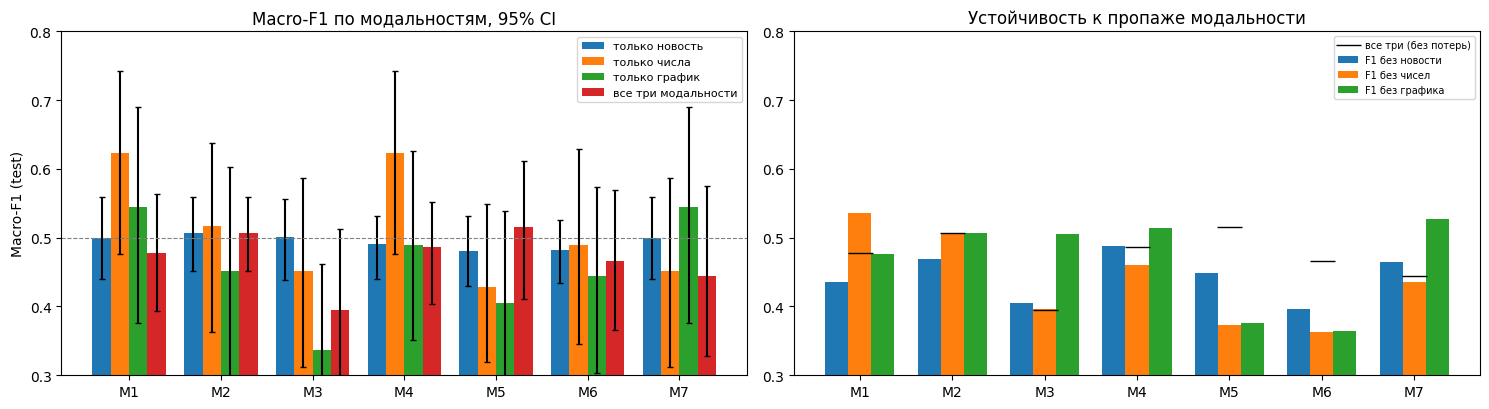

In [22]:
import matplotlib.pyplot as plt
names = list(main_results()); short = [n.split("_")[0] for n in names]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
w = 0.2
for j, mode in enumerate(MODE_MODS):
    st = [run_stats(RESULTS[n]["runs"][mode]) for n in names]
    f = np.array([s["macro_f1"] for s in st]); err = np.array([[s["macro_f1"] - s["f1_lo"] for s in st], [s["f1_hi"] - s["macro_f1"] for s in st]])
    ax[0].bar(np.arange(len(names)) + (j - 1.5) * w, f, w, yerr=err, label=MODE_RU[mode], capsize=2)
ax[0].axhline(0.5, color="gray", lw=0.8, ls="--"); ax[0].set_xticks(range(len(names))); ax[0].set_xticklabels(short)
ax[0].set_ylim(0.3, 0.8); ax[0].set_ylabel("Macro-F1 (test)"); ax[0].legend(fontsize=8); ax[0].set_title("Macro-F1 по модальностям, 95% CI")
for j, k in enumerate(("F1 без новости", "F1 без чисел", "F1 без графика")):
    ax[1].bar(np.arange(len(names)) + (j - 1) * 0.25, COMP.loc[names, k].astype(float), 0.25, label=k)
ax[1].plot(range(len(names)), [run_stats(RESULTS[n]["runs"]["all"])["macro_f1"] for n in names], "k_", ms=18, label="все три (без потерь)")
ax[1].set_xticks(range(len(names))); ax[1].set_xticklabels(short); ax[1].set_ylim(0.3, 0.8); ax[1].legend(fontsize=7); ax[1].set_title("Устойчивость к пропаже модальности")
plt.tight_layout(); plt.savefig(f"{ART}/fig_f1_robust.png", dpi=130); plt.show()

## 6. Лучшая модель: абляции, permutation test, режимы, ошибки, калибровка
(требования отчёта 6–9: unimodal vs fusion, абляции модальностей, анализ ошибок, вывод о полезности)

In [23]:
cfg, res, ds = BEST_CFG, BEST_RES, DS_MAIN
full = res["runs"]["all"]; yf = yh_of(full); boots = get_boot(ds)
print("Лучшая модель:", BEST, "| слияние:", full.fusion_used, "| веса late:" if full.weights else "", full.weights or "")
rows = {"полная модель (все три)": dict(F1=run_stats(full)["macro_f1"], delta=0.0, lo=0.0, hi=0.0, p=float("nan"))}
def add(label, yh):
    g = gain_stats(Y_TE, yf, yh, G_TE, boots)            # A = полная, B = абляция; Δ>0 значит модальность/блок полезны
    rows[label] = dict(F1=macro_f1(Y_TE, yh), delta=g["delta"], lo=g["lo"], hi=g["hi"], p=g["p_perm"])
# (а) переобучение без модальности
for drop, nm in (("text", "новость"), ("num", "числа"), ("img", "график")):
    r = fit_mode(cfg, ds, tuple(m for m in ("text", "num", "img") if m != drop)); add(f"переобучение без: {nm}", yh_of(r))
# (б) модальность пропала только на этапе вывода
for drop, nm in (("text", "новость"), ("num", "числа"), ("img", "график")):
    add(f"вывод без: {nm} (модель обучена на трёх)", (res["robust"][drop] > full.thr).astype(int))
# (в) слияние заменяем на более простое (для xattn это абляция cross-attention)
if cfg["kind"] == "modular":
    alt = "concat" if cfg["fusion"] != "concat" else "late"
    r = fit_mode(cfg, ds, MODE_MODS["all"], fusion=alt); add(f"слияние {cfg['fusion']} -> {alt}", yh_of(r))
release_all()
ABL = pd.DataFrame(rows).T.rename(columns={"F1": "Macro-F1", "delta": "Δ (полная − без)", "lo": "CI low", "hi": "CI high", "p": "p (permutation)"})
TABLES["t6_ablation"] = ABL; display(ABL.round(3))
print("Δ>0 с CI выше нуля: удаление блока достоверно ухудшает качество, т.е. блок полезен. Пары Δ с CI через 0: вклад не доказан.")
print("\nПрирост «все три» над лучшим одномодальным baseline всех моделей:", {k: round(v, 3) for k, v in GAIN[BEST].items()})
own = {m: run_stats(res["runs"][m])["macro_f1"] for m in ("text", "num", "img")}
print("Macro-F1 одномодальных прогонов этой модели:", {MODE_RU[k]: round(v, 3) for k, v in own.items()}, "| все три:", round(run_stats(full)["macro_f1"], 3))

Лучшая модель: M2_ruBERT-tiny2+DINOv2-S+window_late | слияние: late | веса late: {'text': 1.0, 'img': 0.0, 'num': 0.0}


,Macro-F1,Δ (полная − без),CI low,CI high,p (permutation)
полная модель (все три),0.506,0.000,0.000,0.000,NaN
переобучение без: новость,0.517,-0.011,-0.147,0.157,0.562
переобучение без: числа,0.506,0.000,0.000,0.000,1.000
переобучение без: график,0.506,0.000,0.000,0.000,1.000
вывод без: новость (модель обучена на трёх),0.468,0.038,-0.118,0.192,0.317
вывод без: числа (модель обучена на трёх),0.506,0.000,0.000,0.000,1.000
вывод без: график (модель обучена на трёх),0.506,0.000,0.000,0.000,1.000
слияние late -> concat,0.498,0.008,-0.135,0.140,0.450


Δ>0 с CI выше нуля: удаление блока достоверно ухудшает качество, т.е. блок полезен. Пары Δ с CI через 0: вклад не доказан.

Прирост «все три» над лучшим одномодальным baseline всех моделей: {'delta': -0.117, 'lo': -0.251, 'hi': 0.039, 'p_perm': 0.931}
Macro-F1 одномодальных прогонов этой модели: {'только новость': 0.506, 'только числа': 0.517, 'только график': 0.451} | все три: 0.506


In [24]:
ds = DS_MAIN; d = ds.df.iloc[TE]; vol = ds.stats[TE, 9]; vthr = np.median(ds.stats[ds.idx["train"], 9])
L = d.text.str.len().values; Lm = np.median(L); half = np.arange(len(TE)) < len(TE) // 2
masks = {"весь test": np.ones(len(TE), bool),
         "новость в торговую сессию": (d.session == "intraday").values, "новость вне сессии": (d.session != "intraday").values,
         "длинная новость (> медианы test)": L > Lm, "короткая новость": L <= Lm,
         "высокая волатильность (> медианы train)": vol > vthr, "низкая волатильность": vol <= vthr,
         "эвристика утечки в тексте: есть": d.leak_flag.values, "эвристика утечки в тексте: нет": ~d.leak_flag.values,
         "первая половина test по времени": half, "вторая половина test": ~half}
rows = {}
for nm, mk in masks.items():
    if mk.sum() < 30: rows[nm] = {"n": int(mk.sum())}; continue
    f = {m: macro_f1(Y_TE[mk], yh_of(BEST_RES["runs"][m])[mk]) for m in MODE_MODS}
    rows[nm] = {"n": int(mk.sum()), **{MODE_RU[m]: f[m] for m in MODE_MODS}, "Δ все три − лучший одномодальный": f["all"] - max(f["text"], f["num"], f["img"])}
REG = pd.DataFrame(rows).T; TABLES["t7_regimes"] = REG; display(REG.round(3))
print("Подвыборки небольшие: различия в 0.03–0.05 здесь в пределах шума, смотрите на знак и согласованность по режимам.")

,n,только новость,только числа,только график,все три модальности,Δ все три − лучший одномодальный
весь test,437.0,0.506,0.517,0.451,0.506,-0.011
новость в торговую сессию,332.0,0.498,0.509,0.438,0.498,-0.011
новость вне сессии,105.0,0.523,0.543,0.491,0.523,-0.019
длинная новость (> медианы test),218.0,0.491,0.518,0.394,0.491,-0.026
короткая новость,219.0,0.522,0.515,0.505,0.522,0.000
высокая волатильность (> медианы train),0.0,NaN,NaN,NaN,NaN,NaN
низкая волатильность,437.0,0.506,0.517,0.451,0.506,-0.011
эвристика утечки в тексте: есть,2.0,NaN,NaN,NaN,NaN,NaN
эвристика утечки в тексте: нет,435.0,0.509,0.520,0.451,0.509,-0.011
первая половина test по времени,218.0,0.474,0.473,0.485,0.474,-0.011


Подвыборки небольшие: различия в 0.03–0.05 здесь в пределах шума, смотрите на знак и согласованность по режимам.


Матрица ошибок (все три), строки = факт, столбцы = прогноз:


,прогноз: падение,прогноз: рост
факт: падение,92,101
факт: рост,113,131


доля прогнозов «рост»: 0.53; доля роста в test: 0.56


,n,точность fusion,точность только новость,точность только числа,точность только график
три одномодальные согласны,124.0,0.524,0.524,0.524,0.524
одномодальные расходятся,313.0,0.505,0.505,0.514,0.431



Конфликт модальностей, fusion прав:
- 2024-02-13 21:28 | факт рост (ret +0.693%) | новость/число/график/fusion: ↑/↓/↓/↑ | Российские ИИ-решения стали одним из первых в мире, сдавших экзамен на выпускника медицинского ВУЗа по направлению подготовки «Лечебное дело». Это стало первым 
- 2024-02-14 11:47 | факт рост (ret +0.693%) | новость/число/график/fusion: ↑/↓/↓/↑ | В Сбербанке раскрыли число ежедневных мошеннических звонков россиянам. Ежедневно мошенники связываются с клиентами банка в том числе через мессенджеры, заявил з
- 2024-02-14 14:53 | факт рост (ret +0.693%) | новость/число/график/fusion: ↑/↓/↓/↑ | В России начнут готовить специалистов по борьбе с мошенниками. Глава Центробанка Эльвира Набиуллина рассказала, что отечественному финансовому рынку требуется о
- 2024-02-14 15:47 | факт рост (ret +0.693%) | новость/число/график/fusion: ↑/↓/↓/↑ | В России создадут отраслевой клуб по искусственному интеллекту в здравоохранении. В рамках инициативы Сбербанка создадут новый клуб по И

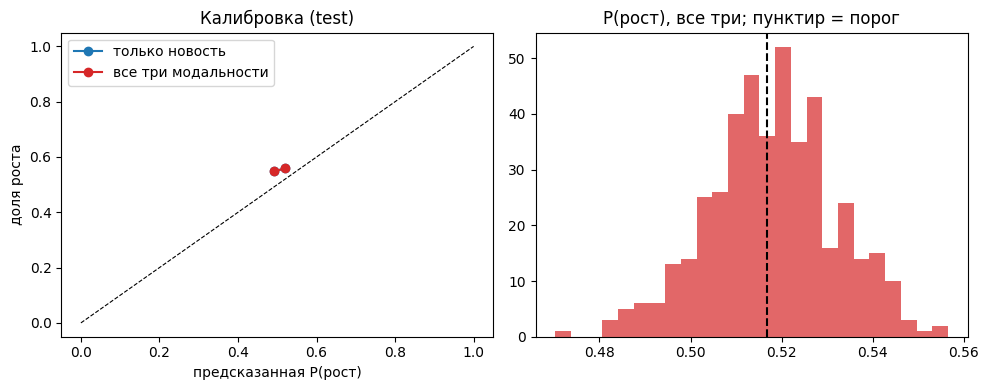

In [25]:
from sklearn.metrics import confusion_matrix
run = BEST_RES["runs"]["all"]; yh = {m: yh_of(BEST_RES["runs"][m]) for m in MODE_MODS}
cm = confusion_matrix(Y_TE, yh["all"], labels=[0, 1])
print("Матрица ошибок (все три), строки = факт, столбцы = прогноз:"); display(pd.DataFrame(cm, index=["факт: падение", "факт: рост"], columns=["прогноз: падение", "прогноз: рост"]))
print(f"доля прогнозов «рост»: {yh['all'].mean():.2f}; доля роста в test: {Y_TE.mean():.2f}")
uni = np.column_stack([yh["text"], yh["num"], yh["img"]]); agree = (uni.min(1) == uni.max(1))
cat = np.where(agree, "три одномодальные согласны", "одномодальные расходятся")
rows = {}
for c in ("три одномодальные согласны", "одномодальные расходятся"):
    mk = cat == c
    if mk.sum(): rows[c] = {"n": int(mk.sum()), "точность fusion": float((yh["all"][mk] == Y_TE[mk]).mean()),
                            **{f"точность {MODE_RU[m]}": float((yh[m][mk] == Y_TE[mk]).mean()) for m in ("text", "num", "img")}}
AGR = pd.DataFrame(rows).T; TABLES["t8_agreement"] = AGR; display(AGR.round(3))
d = DS_MAIN.df.iloc[TE].reset_index(drop=True)
def show(mask, title, k=4):
    print(f"\n{title}")
    for i in np.where(mask)[0][:k]:
        print(f"- {d.published[i]:%Y-%m-%d %H:%M} | факт {'рост' if Y_TE[i] else 'падение'} (ret {d.ret_next[i]:+.3%}) | новость/число/график/fusion: "
              f"{'↑' if yh['text'][i] else '↓'}/{'↑' if yh['num'][i] else '↓'}/{'↑' if yh['img'][i] else '↓'}/{'↑' if yh['all'][i] else '↓'} | {d.text_short[i][:160]}")
show(~agree & (yh["all"] == Y_TE), "Конфликт модальностей, fusion прав:")
show(~agree & (yh["all"] != Y_TE), "Конфликт модальностей, fusion ошибся:")
show(agree & (yh["all"] != Y_TE), "Все согласны, но ошиблись (шум рынка, а не конфликт):")
big = np.argsort(-np.abs(d.ret_next.values))[:30]; print(f"\nСреди 30 самых больших по модулю движений fusion прав в {(yh['all'][big] == Y_TE[big]).mean():.0%} случаев")
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for m, c in (("text", "tab:blue"), ("all", "tab:red")):
    p = BEST_RES["runs"][m].pt; b = np.minimum((p * 10).astype(int), 9)
    xs = [p[b == k].mean() for k in range(10) if (b == k).sum() >= 5]; ys = [Y_TE[b == k].mean() for k in range(10) if (b == k).sum() >= 5]
    ax[0].plot(xs, ys, "o-", color=c, label=MODE_RU[m])
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set_xlabel("предсказанная P(рост)"); ax[0].set_ylabel("доля роста"); ax[0].legend(); ax[0].set_title("Калибровка (test)")
ax[1].hist(run.pt, bins=25, color="tab:red", alpha=0.7); ax[1].axvline(run.thr, color="k", ls="--"); ax[1].set_title("P(рост), все три; пунктир = порог")
plt.tight_layout(); plt.savefig(f"{ART}/fig_calibration.png", dpi=130); plt.show()

## 7. Задание 4: применение лучшей схемы к другой компании
Тема ВКР здесь не используется, поэтому применить лучшую модель мне не к чему, следовательно, использовать акцию для примера не вижу смысла, так как для действительно хороших результатов требуется тяжелая модель, много ресурсов, много времени и тонкая настройка, не говоря уже о более качественном наборе данных

## 8. Артефакты (задание 7) и черновик вывода (задание 6)

In [26]:
import zipfile, shutil
# таблицы
for k, df in TABLES.items(): df.to_csv(f"{ART}/{k}.csv", encoding="utf-8-sig")
with open(f"{ART}/report_tables.md", "w", encoding="utf-8") as f:
    for k, df in TABLES.items(): f.write(f"\n### {k}\n\n{df.round(3).to_markdown()}\n")
# таблица моделей
pd.DataFrame({n: {k: v for k, v in r["cfg"].items()} for n, r in main_results().items()}).T.to_csv(f"{ART}/models_table.csv", encoding="utf-8-sig")
# прогнозы test (для проверки и анализа ошибок)
pr = DS_MAIN.df.iloc[TE][["sample_id", "published", "anchor_date", "label", "ret_next"]].reset_index(drop=True)
for n, r in main_results().items():
    for m in MODE_MODS: pr[f"{n.split('_')[0]}|{m}"] = r["runs"][m].pt
pr.to_csv(f"{ART}/predictions_test.csv", index=False)
# журнал исключённых наблюдений и отчёт по данным из задания 2
for fn in ("exclusions.csv", "bad_images.csv", "data_report.md"):
    if os.path.exists(f"{SBER_OUT}/{fn}"): shutil.copy(f"{SBER_OUT}/{fn}", f"{ART}/sber_{fn}")
# правила синхронизации и схема данных
open(f"{ART}/sync_rules.md", "w", encoding="utf-8").write(f"""# Правила синхронизации (из task2_sync.py)
- все времена в МСК; время в Lenta-news без пояса принято за МСК
- якорь A = последний торговый день, сессия которого закрыта к моменту публикации; окно = {WINDOW} дневных свечей до A включительно
- цель = знак close(A+1)/close(A) − 1; торговый календарь строится по свечам MOEX; пропуски не интерполируются (образец исключается)
- дубликаты новостей удалены до разбиения; split хронологический 70/15/15 по якорной дате с зазором 1 торговый день (embargo)
- решение «рост», если P(рост) > доля роста в train; выбор гиперпараметров по val, оценка на test, CI блочным bootstrap по якорным датам
""")
json.dump({c: str(t) for c, t in DS_MAIN.df.dtypes.items()}, open(f"{ART}/data_schema.json", "w"), ensure_ascii=False, indent=1)
open(f"{ART}/sources.md", "w", encoding="utf-8").write("""# Источники данных
- Новости: https://huggingface.co/datasets/rustemgareev/lenta-news (раздел «Экономика»; лицензия на странице «unknown», корпус не публиковать)
- Котировки: MOEX ISS, https://iss.moex.com/iss (TQBR, дневные свечи)
""")
json.dump(ENV_INFO, open(f"{ART}/env.json", "w"), indent=1)
with zipfile.ZipFile(f"{WORK}/lab2_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for fn in os.listdir(ART):
        if not fn.startswith("light_"): z.write(f"{ART}/{fn}", fn)
print("артефакты:", sorted(os.listdir(ART)), "\nархив:", f"{WORK}/lab2_artifacts.zip")

артефакты: ['data_schema.json', 'env.json', 'fig_calibration.png', 'fig_f1_robust.png', 'light_M1_E5-base_CLIP-B32_stats_concat.pkl', 'light_M2_ruBERT-tiny2_DINOv2-S_window_late.pkl', 'light_M3_BGE-M3_SigLIP-B_both_gated.pkl', 'light_M4_SBERT-large-ru_CLIP-B16_stats_xattn.pkl', 'light_M5_LLaVA-interleave-0.5B_joint.pkl', 'light_M6_Qwen2-VL-2B_joint.pkl', 'light_M7_E5-base_CLIP-B32_both_gated.pkl', 'models_table.csv', 'naive.csv', 'params_journal.jsonl', 'predictions_test.csv', 'report_tables.md', 'sber_bad_images.csv', 'sber_data_report.md', 'sber_exclusions.csv', 'sources.md', 'sync_rules.md', 't1_text.csv', 't2_num.csv', 't3_img.csv', 't4_all.csv', 't5_composite.csv', 't6_ablation.csv', 't7_regimes.csv', 't8_agreement.csv'] 
архив: /content/drive/MyDrive/ВКР/Лабораторная Работа 2/lab2_artifacts.zip


In [27]:
# Черновик цифр для вывода (задание 6). Формулировки и интерпретацию пишите сами, опираясь на таблицы выше.
g = GAIN[BEST]; full = BEST_RES["runs"]["all"]
print(f"Лучшая схема: {BEST}")
print(f"1) Прирост «все три» над лучшим одномодальным baseline: Δ Macro-F1 = {g['delta']:+.3f}, 95% CI [{g['lo']:+.3f}; {g['hi']:+.3f}], p(perm) = {g['p_perm']:.3f}; "
      f"гипотеза Δ ≥ {HYP_GAIN} и CI > 0: {'ПОДТВЕРЖДЕНА' if g['delta'] >= HYP_GAIN and g['lo'] > 0 else 'НЕ подтверждена'}")
ab = TABLES["t6_ablation"]; dr = ab[ab.index.str.startswith("переобучение без")]["Δ (полная − без)"].astype(float)
print("2) Вклад модальности (потеря Macro-F1 при удалении и переобучении):", {k.replace('переобучение без: ', ''): round(v, 3) for k, v in dr.items()}, "| наибольший вклад:", dr.idxmax().replace("переобучение без: ", ""))
print("3) Режимы (Δ все три − лучший одномодальный):"); print(TABLES["t7_regimes"]["Δ все три − лучший одномодальный"].dropna().round(3).to_string())
print(f"4) Цена усложнения: latency p50 {BEST_RES['latency']['p50_ms']:.0f} мс, ${BEST_RES['latency']['mean_ms']/3600*GPU_USD_PER_HOUR:.4f} за 1000 прогнозов "
      f"(лучший одномодальный baseline тоже можно измерить отдельно: выше в таблицах)")

Лучшая схема: M2_ruBERT-tiny2+DINOv2-S+window_late
1) Прирост «все три» над лучшим одномодальным baseline: Δ Macro-F1 = -0.117, 95% CI [-0.251; +0.039], p(perm) = 0.931; гипотеза Δ ≥ 0.03 и CI > 0: НЕ подтверждена
2) Вклад модальности (потеря Macro-F1 при удалении и переобучении): {'новость': -0.011, 'числа': 0.0, 'график': 0.0} | наибольший вклад: числа
3) Режимы (Δ все три − лучший одномодальный):
весь test                          -0.011
новость в торговую сессию          -0.011
новость вне сессии                 -0.019
длинная новость (> медианы test)   -0.026
короткая новость                    0.000
низкая волатильность               -0.011
эвристика утечки в тексте: нет     -0.011
первая половина test по времени    -0.011
вторая половина test               -0.028
4) Цена усложнения: latency p50 20 мс, $0.0604 за 1000 прогнозов (лучший одномодальный baseline тоже можно измерить отдельно: выше в таблицах)


## Соответствие разделам отчёта
| Раздел отчёта | Где |
|---|---|
| 1–4 обзор, схема объекта, паспорта, правила синхронизации | задания 1–2 (docx), `artifacts/sync_rules.md`, `data_report.md`, паспорт новой компании в разделе 7 |
| 5 сравнение 7–8 моделей | раздел 3, `models_table.csv`, `params_journal.jsonl` |
| 6 unimodal baseline и fusion | таблицы 1–4 |
| 7 абляции | `t6_ablation`, раздел 6 |
| 8 анализ ошибок | `t7_regimes`, `t8_agreement`, примеры, калибровка |
| 9 вывод | ячейка «черновик вывода» + задание 4 |